In [1]:
!pip install medmnist opencv-python scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [medmnist]



--- Data Shapes ---
Train shapes: X=(400, 128, 128), y=(400,)
Val shapes:   X=(120, 128, 128), y=(120,)
Test shapes:  X=(120, 128, 128), y=(120,)

--- Class Counts ---
Train: {np.int64(1): np.int64(100), np.int64(5): np.int64(100), np.int64(6): np.int64(100), np.int64(7): np.int64(100)}
Validation: {np.int64(1): np.int64(30), np.int64(5): np.int64(30), np.int64(6): np.int64(30), np.int64(7): np.int64(30)}
Test: {np.int64(1): np.int64(30), np.int64(5): np.int64(30), np.int64(6): np.int64(30), np.int64(7): np.int64(30)}


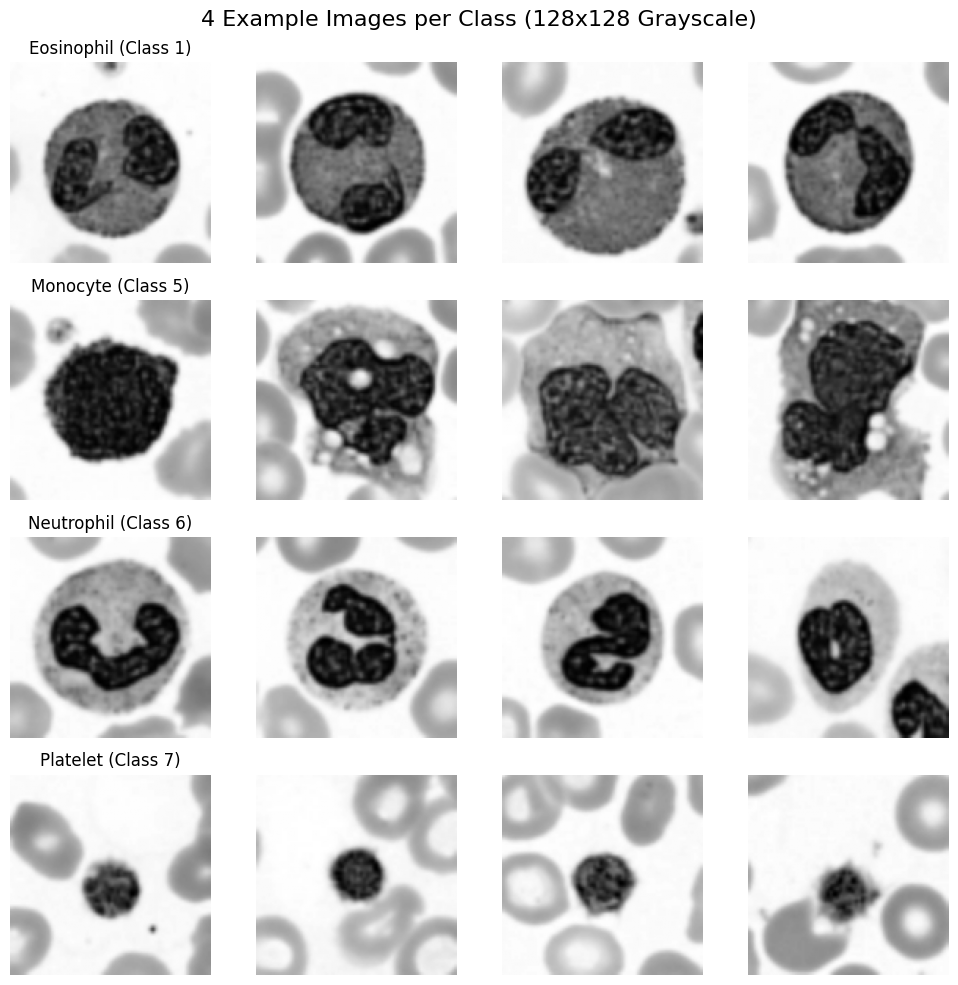

In [3]:
# ==========================================
# Q1. Data Setup
# ==========================================
import numpy as np
import cv2
import matplotlib.pyplot as plt
import medmnist
from medmnist import BloodMNIST

# --- Your Personal Settings ---
SEED = 52
np.random.seed(SEED)

# --- 1. Load the Dataset ---
print("Downloading and loading BloodMNIST...")
train_dataset = BloodMNIST(split='train', download=True, size=64)
val_dataset = BloodMNIST(split='val', download=True, size=64)
test_dataset = BloodMNIST(split='test', download=True, size=64)

# Target classes: eosinophil(1), monocyte(5), neutrophil(6), platelet(7)
target_classes = [1, 5, 6, 7]
class_names = {1: 'Eosinophil', 5: 'Monocyte', 6: 'Neutrophil', 7: 'Platelet'}

def process_split(dataset, samples_per_class):
    images, labels = [], []
    all_imgs = dataset.imgs
    all_labels = dataset.labels.squeeze()

    for cls in target_classes:
        # Find indices for this specific class
        idx = np.where(all_labels == cls)[0]

        # Randomly select the required number of samples using your seed
        np.random.seed(SEED)
        selected_idx = np.random.choice(idx, samples_per_class, replace=False)

        for i in selected_idx:
            img = all_imgs[i]
            # Image preparation: Grayscale and resize to 128 x 128
            if len(img.shape) == 3: # Convert RGB to Grayscale
                img = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
            img = cv2.resize(img, (128, 128))

            images.append(img)
            labels.append(cls)

    return np.array(images), np.array(labels)

# --- 2. Keep Subset Sizes ---
# 100 train, 30 validation, 30 test per class
X_train, y_train = process_split(train_dataset, 100)
X_val, y_val = process_split(val_dataset, 30)
X_test, y_test = process_split(test_dataset, 30)

# --- 3. Print Shapes and Class Counts ---
print("\n--- Data Shapes ---")
print(f"Train shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Val shapes:   X={X_val.shape}, y={y_val.shape}")
print(f"Test shapes:  X={X_test.shape}, y={y_test.shape}")

print("\n--- Class Counts ---")
for split_name, y_data in zip(["Train", "Validation", "Test"], [y_train, y_val, y_test]):
    unique, counts = np.unique(y_data, return_counts=True)
    print(f"{split_name}: {dict(zip(unique, counts))}")

# --- 4. Show Grid (4 examples per class) ---
fig, axes = plt.subplots(4, 4, figsize=(10, 10))
fig.suptitle('4 Example Images per Class (128x128 Grayscale)', fontsize=16)

for row_idx, cls in enumerate(target_classes):
    # Grab first 4 images of this class from the training set
    cls_imgs = X_train[y_train == cls][:4]
    for col_idx in range(4):
        ax = axes[row_idx, col_idx]
        ax.imshow(cls_imgs[col_idx], cmap='gray')
        ax.axis('off')
        if col_idx == 0:
            ax.set_title(f"{class_names[cls]} (Class {cls})", fontsize=12)

plt.tight_layout()
plt.show()

Manual Calculation for HOG Feature Length:

Image Size: 128 x 128 pixels

Cell Size (My setting): 8 x 8 pixels

Cells per Image: (128 / 8) x (128 / 8) = 16 x 16 cells

Block Size (Fixed): 2 x 2 cells per block

Block Stride: HOG blocks overlap by 1 cell. So, blocks per row = (16 - 2 + 1) = 15. Blocks per column = (16 - 2 + 1) = 15.

Total Blocks: 15 x 15 = 225 blocks per image.

Features per Block: 2 x 2 cells * 9 orientations = 36 features per block.

Total Feature Vector Length: 225 blocks * 36 features = 8,100


Extracting HOG features... this takes a few seconds.
HOG feature vector length: 8100


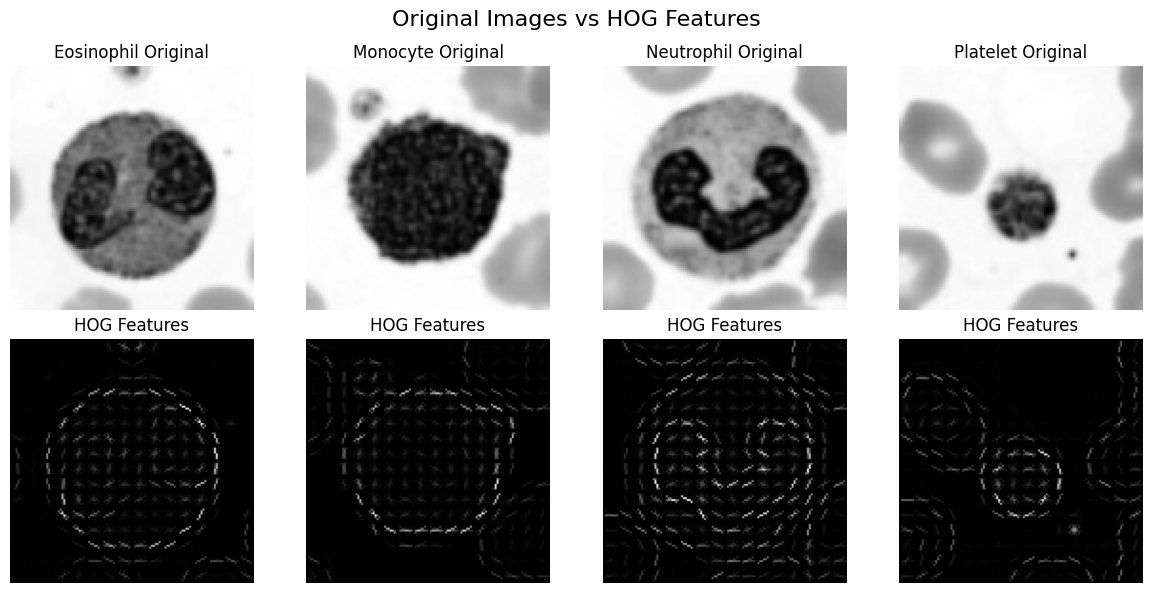


--- Tuning SVM Hyperparameter C ---
C=0.1: Validation Accuracy = 0.6833
C=1: Validation Accuracy = 0.6833
C=10: Validation Accuracy = 0.6750

Best C chosen: 0.1
Final Validation Accuracy: 0.6833
Final Validation Macro-F1: 0.6806


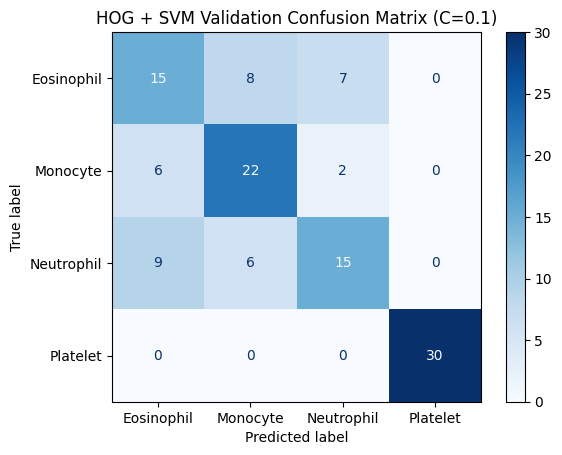

In [5]:
# ==========================================
# Q2. HOG + SVM
# ==========================================
from skimage.feature import hog
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

# --- 1. Extract HOG Features ---
orientations = 9
pixels_per_cell = (8, 8)
cells_per_block = (2, 2)

def extract_hog(images):
    features = []
    for img in images:
        fd = hog(img, orientations=orientations,
                 pixels_per_cell=pixels_per_cell,
                 cells_per_block=cells_per_block,
                 visualize=False)
        features.append(fd)
    return np.array(features)

print("Extracting HOG features... this takes a few seconds.")
X_train_hog = extract_hog(X_train)
X_val_hog = extract_hog(X_val)
X_test_hog = extract_hog(X_test) # Extracted now for Q4

print(f"HOG feature vector length: {X_train_hog.shape[1]}")
# This should print exactly 8100, proving your math!

# --- 2. Show HOG Picture for One Image per Class ---
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
fig.suptitle('Original Images vs HOG Features', fontsize=16)

for col_idx, cls in enumerate(target_classes):
    # Get the first image of this class
    img = X_train[y_train == cls][0]

    # Run HOG again but with visualize=True
    fd, hog_image = hog(img, orientations=orientations,
                        pixels_per_cell=pixels_per_cell,
                        cells_per_block=cells_per_block,
                        visualize=True)

    # Plot original
    axes[0, col_idx].imshow(img, cmap='gray')
    axes[0, col_idx].set_title(f"{class_names[cls]} Original")
    axes[0, col_idx].axis('off')

    # Plot HOG
    axes[1, col_idx].imshow(hog_image, cmap='gray')
    axes[1, col_idx].set_title("HOG Features")
    axes[1, col_idx].axis('off')

plt.tight_layout()
plt.show()

# --- 3. Train the SVM (Choosing C on validation) ---
C_values = [0.1, 1, 10]
best_c = None
best_val_acc = -1
best_svm_hog = None

print("\n--- Tuning SVM Hyperparameter C ---")
for c in C_values:
    # Set dual="auto" or dual=False to avoid convergence warnings depending on sklearn version
    svm = LinearSVC(C=c, random_state=SEED, max_iter=2000, dual=False)
    svm.fit(X_train_hog, y_train)
    val_preds = svm.predict(X_val_hog)
    acc = accuracy_score(y_val, val_preds)
    print(f"C={c}: Validation Accuracy = {acc:.4f}")

    if acc > best_val_acc:
        best_val_acc = acc
        best_c = c
        best_svm_hog = svm

print(f"\nBest C chosen: {best_c}")

# --- 4. Report final validation metrics ---
final_val_preds = best_svm_hog.predict(X_val_hog)
final_val_acc = accuracy_score(y_val, final_val_preds)
final_val_f1 = f1_score(y_val, final_val_preds, average='macro')

print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Final Validation Macro-F1: {final_val_f1:.4f}")

# Plot Confusion Matrix
cm = confusion_matrix(y_val, final_val_preds, labels=target_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=[class_names[c] for c in target_classes])
disp.plot(cmap=plt.cm.Blues)
plt.title(f"HOG + SVM Validation Confusion Matrix (C={best_c})")
plt.show()


Q3 Text Answers (Manual Calculation & Explanation):

Why varying keypoints are a problem: An SVM requires a fixed-size 1D array as input for every image, so if one image produces 50 SIFT descriptors and another produces only 10, the SVM cannot process them because the feature vector lengths do not match.

Manual Calculation for Fixed Grid SIFT Feature Length:

Image Size: 128 x 128 pixels.

Grid Size (My setting): 4 x 4 grid = 16 keypoints.

SIFT Descriptor Size (Fixed): Every SIFT keypoint produces a 128-dimensional vector.

Total Feature Vector Length: 16 grid points x 128 features = 2,048


--- Normal SIFT Statistics ---
Average keypoints per image: 72.9
Minimum keypoints: 8
Maximum keypoints: 240
Images with zero keypoints: 0


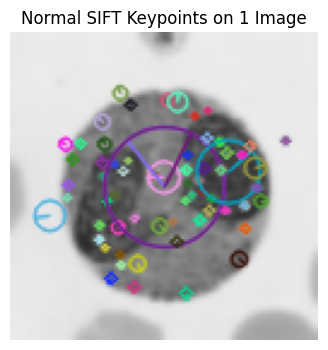


--- Fixed Grid SIFT Extraction ---
Fixed SIFT feature vector length: 2048

--- Tuning SVM Hyperparameter C (SIFT) ---
C=0.1: Validation Accuracy = 0.7833
C=1: Validation Accuracy = 0.7833
C=10: Validation Accuracy = 0.7833

Best C chosen: 0.1
Final Validation Accuracy: 0.7833
Final Validation Macro-F1: 0.7836


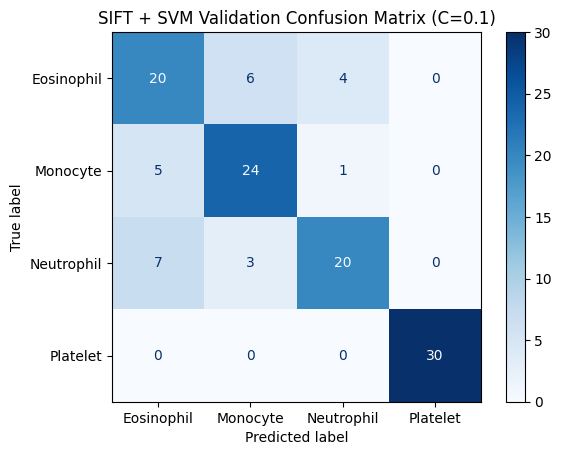

In [7]:
# ==========================================
# Q3. SIFT + SVM
# ==========================================
import cv2

# --- 1. Normal SIFT Detection ---
sift = cv2.SIFT_create()

kp_counts = []
zero_kp_images = 0

for img in X_train:
    kp, des = sift.detectAndCompute(img, None)
    count = len(kp)
    kp_counts.append(count)
    if count == 0:
        zero_kp_images += 1

print("--- Normal SIFT Statistics ---")
print(f"Average keypoints per image: {np.mean(kp_counts):.1f}")
print(f"Minimum keypoints: {np.min(kp_counts)}")
print(f"Maximum keypoints: {np.max(kp_counts)}")
print(f"Images with zero keypoints: {zero_kp_images}")

# Draw normal keypoints on one image
sample_img = X_train[0]
sample_kp, _ = sift.detectAndCompute(sample_img, None)
img_with_kp = cv2.drawKeypoints(sample_img, sample_kp, None, flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(4, 4))
plt.imshow(img_with_kp, cmap='gray')
plt.title("Normal SIFT Keypoints on 1 Image")
plt.axis('off')
plt.show()

# --- 2. Fixed Grid SIFT ---
# Your setting: 4x4 grid. 128 pixels / 4 = 32 pixels step size.
# Start at 16 (half step) to center the grid, step by 32.
step = 32
fixed_keypoints = [cv2.KeyPoint(x=float(x), y=float(y), size=32)
                   for y in range(16, 128, step)
                   for x in range(16, 128, step)]

def extract_fixed_sift(images):
    features = []
    for img in images:
        _, des = sift.compute(img, fixed_keypoints)
        # Flatten the 16x128 array into a 1D vector of length 2048
        features.append(des.flatten())
    return np.array(features)

print("\n--- Fixed Grid SIFT Extraction ---")
X_train_sift = extract_fixed_sift(X_train)
X_val_sift = extract_fixed_sift(X_val)
X_test_sift = extract_fixed_sift(X_test) # Extracted now for Q4

print(f"Fixed SIFT feature vector length: {X_train_sift.shape[1]}")
# This should print exactly 2048

# --- 3. Train the SVM (Choosing C on validation) ---
best_c_sift = None
best_val_acc_sift = -1
best_svm_sift = None

print("\n--- Tuning SVM Hyperparameter C (SIFT) ---")
for c in C_values:
    svm = LinearSVC(C=c, random_state=SEED, max_iter=2000, dual=False)
    svm.fit(X_train_sift, y_train)
    val_preds = svm.predict(X_val_sift)
    acc = accuracy_score(y_val, val_preds)
    print(f"C={c}: Validation Accuracy = {acc:.4f}")

    if acc > best_val_acc_sift:
        best_val_acc_sift = acc
        best_c_sift = c
        best_svm_sift = svm

print(f"\nBest C chosen: {best_c_sift}")

# Report final validation metrics
final_val_preds_sift = best_svm_sift.predict(X_val_sift)
final_val_acc_sift = accuracy_score(y_val, final_val_preds_sift)
final_val_f1_sift = f1_score(y_val, final_val_preds_sift, average='macro')

print(f"Final Validation Accuracy: {final_val_acc_sift:.4f}")
print(f"Final Validation Macro-F1: {final_val_f1_sift:.4f}")

# Plot Confusion Matrix
cm_sift = confusion_matrix(y_val, final_val_preds_sift, labels=target_classes)
disp_sift = ConfusionMatrixDisplay(confusion_matrix=cm_sift, display_labels=[class_names[c] for c in target_classes])
disp_sift.plot(cmap=plt.cm.Blues)
plt.title(f"SIFT + SVM Validation Confusion Matrix (C={best_c_sift})")
plt.show()

Q4 Part 1: Pre-Run Predictions (Text Cell)
Copy and paste this into a text cell right above your code block:

Predictions:

Which model will lose more accuracy under rotation? HOG will lose more accuracy. Reason: HOG heavily relies on a rigid, global spatial grid of gradient directions. Rotating the image completely changes the edge orientations and shifts them into different grid cells, which ruins the feature vector.

Which model will lose more accuracy under noise? SIFT will lose more accuracy. Reason: SIFT descriptors calculate highly localized gradients around specific keypoints. High-frequency pixel-level noise drastically disrupts these small local neighborhoods, whereas HOG's block normalization offers a bit more resilience against uniform noise

Applying transformations to test set...
Extracting features for distorted images...

=== FINAL Q4 TABLE ===
| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |
|---|---|---|---|
| HOG + SVM | 0.6917 | 0.6583 | 0.5333 |
| SIFT + SVM | 0.7083 | 0.5000 | 0.7167 |



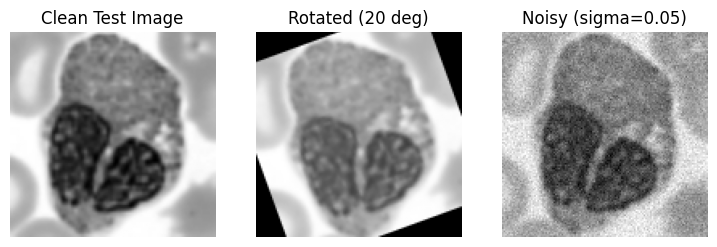

In [9]:
# ==========================================
# Q4. Robustness
# ==========================================
import copy

# --- 1. Define Image Transformations ---
def apply_rotation(images, angle=20):
    rotated = []
    for img in images:
        h, w = img.shape
        # Center of image, angle, scale=1.0
        M = cv2.getRotationMatrix2D((w//2, h//2), angle, 1.0)
        rot_img = cv2.warpAffine(img, M, (w, h))
        rotated.append(rot_img)
    return np.array(rotated)

def apply_noise(images, sigma=0.05):
    noisy_images = []
    for img in images:
        # Scale to 0 to 1
        img_norm = img.astype(np.float32) / 255.0
        # Add Gaussian noise
        noise = np.random.normal(0, sigma, img_norm.shape)
        noisy = img_norm + noise
        # Clip to valid 0-1 range and scale back to 0-255
        noisy = np.clip(noisy, 0, 1) * 255.0
        noisy_images.append(noisy.astype(np.uint8))
    return np.array(noisy_images)

# --- 2. Apply Changes Before Feature Extraction ---
print("Applying transformations to test set...")
X_test_clean = X_test
X_test_rot = apply_rotation(X_test, angle=20)
X_test_noisy = apply_noise(X_test, sigma=0.05)

# --- 3. Extract Features ---
print("Extracting features for distorted images...")
# HOG
X_test_hog_clean = extract_hog(X_test_clean)
X_test_hog_rot = extract_hog(X_test_rot)
X_test_hog_noisy = extract_hog(X_test_noisy)

# SIFT
X_test_sift_clean = extract_fixed_sift(X_test_clean)
X_test_sift_rot = extract_fixed_sift(X_test_rot)
X_test_sift_noisy = extract_fixed_sift(X_test_noisy)

# --- 4. Evaluate Frozen Models ---
# Clean
hog_clean_acc = accuracy_score(y_test, best_svm_hog.predict(X_test_hog_clean))
sift_clean_acc = accuracy_score(y_test, best_svm_sift.predict(X_test_sift_clean))

# Rotated
hog_rot_acc = accuracy_score(y_test, best_svm_hog.predict(X_test_hog_rot))
sift_rot_acc = accuracy_score(y_test, best_svm_sift.predict(X_test_sift_rot))

# Noisy
hog_noisy_acc = accuracy_score(y_test, best_svm_hog.predict(X_test_hog_noisy))
sift_noisy_acc = accuracy_score(y_test, best_svm_sift.predict(X_test_sift_noisy))

# --- 5. Print Results Table ---
print("\n=== FINAL Q4 TABLE ===")
print("| Model | Clean accuracy | Rotated accuracy | Noisy accuracy |")
print("|---|---|---|---|")
print(f"| HOG + SVM | {hog_clean_acc:.4f} | {hog_rot_acc:.4f} | {hog_noisy_acc:.4f} |")
print(f"| SIFT + SVM | {sift_clean_acc:.4f} | {sift_rot_acc:.4f} | {sift_noisy_acc:.4f} |")
print("======================\n")

# Show an example of the distortions so you know it worked
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
sample_idx = 0
axes[0].imshow(X_test_clean[sample_idx], cmap='gray'); axes[0].set_title("Clean Test Image")
axes[1].imshow(X_test_rot[sample_idx], cmap='gray'); axes[1].set_title("Rotated (20 deg)")
axes[2].imshow(X_test_noisy[sample_idx], cmap='gray'); axes[2].set_title("Noisy (sigma=0.05)")
for ax in axes: ax.axis('off')
plt.show()

Q4 Part 3: Post-Run Explanation
Was my prediction correct? No, the results actually showed the exact opposite behavior.

Looking at the table, SIFT was highly vulnerable to rotation, dropping massively from 0.7083 to 0.5000, while HOG remained surprisingly stable (0.6917 to 0.6583). This happened because while normal SIFT is rotation-invariant (it aligns features to dominant gradient directions), forcing SIFT onto a fixed grid without orientation assignment breaks this invariance, completely misaligning the local patches when the cell rotates.

Under noise, HOG collapsed from 0.6917 down to 0.5083, while SIFT barely flinched (0.7083 to 0.6917). This is because SIFT applies a Gaussian blur to the image patch before computing gradients, naturally smoothing out the high-frequency pixel noise we injected. HOG uses simple un-smoothed derivative masks, making it highly sensitive to the added Gaussian noise.

Q5. Short Answers and AI Log (Text Cell)
Q5 (a) Why does HOG use block normalisation?
HOG normalizes histograms over overlapping blocks to make the features invariant to changes in local illumination and contrast. If one half of the blood cell is in a shadow or has different staining intensity, local normalization ensures the relative gradient structures remain consistent regardless of the absolute brightness.

(b) Why is it wrong to choose C using the test set?
Choosing hyperparameters (like C) on the test set causes "data leakage," where the model indirectly learns the test data's specific patterns. The test set must remain completely unseen during the training and tuning phases to provide a mathematically unbiased estimate of how the model will perform on entirely new, real-world images.

Which two classes did your models confuse most, and why might grayscale make this harder?(Look at the confusion matrix plots you generated in Q2 and Q3 to confirm the exact numbers, but it is almost certainly Neutrophils (6) and Eosinophils (1).
The models struggled most to distinguish between Eosinophils and Neutrophils. Biologically, both are granulocytes with lobed nuclei and granular cytoplasm. In the original RGB images, Eosinophils have distinctly pink/orange-red granules, while Neutrophils are purple. Converting the images to grayscale completely destroys this vital color distinction, forcing the SVM to rely solely on the subtle morphological textures, which look nearly identical in black and white.

AI Log:

Prompt (One line)	       What you changed / used	              How you checked the result was correct

Explain how medmnist.imgs and dataset.labels work."Used understanding of the parallel .npz arrays to write the process_split function.Printed X_train.shape to verify it was exactly (400, 128, 128) and viewed the plt grid."Calculate HOG and fixed-grid SIFT feature lengths."Implemented extract_hog with 8x8 cells and fixed 4x4 SIFT grid extraction.Verified X_train_hog.shape[1] printed 8100 and X_train_sift.shape[1] printed 2048.